<a href="https://colab.research.google.com/github/Farouk41/Customer_Segmentation_Project/blob/main/Customer_Segmentation_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation Using KMeans and DBSCAN

**Dataset:** Customer Segmentation Dataset (40 customers)  
**Algorithms:** KMeans Clustering and DBSCAN  
**Type:** Unsupervised Machine Learning

**Notebook outline**

- **Part A:** Data preparation (loading, inspection, duplicates, scaling)
- **Part B:** KMeans (K=4 as required, elbow method, final model, 2D/3D visualization)
- **Part C:** DBSCAN (9 experiments, parameter analysis, 2D/3D visualization)
- **Part D:** KMeans vs. DBSCAN comparison
- **Conclusion**

# Part A: Data Preparation

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3D projection)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 110

## A.1 Load the dataset

In [6]:
# NOTE: change the path if your CSV is stored somewhere else
df = pd.read_csv("Customer_Segmentation_Dataset.csv")
df.head()

,Unnamed: 0,Income (k$),Spending Score (1-100),Age
0,0,20,15,22
1,1,22,18,25
2,2,18,12,21
3,3,25,20,28
4,4,23,14,24


The file contains an extra column called `Unnamed: 0`. It is just the old row index that was saved with the CSV, so it carries **no information about the customers** and must be dropped. I also rename `Income (k$)` to `Annual Income (k$)` to match the task description.

In [7]:
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={"Income (k$)": "Annual Income (k$)"})
df.head()

,Annual Income (k$),Spending Score (1-100),Age
0,20,15,22
1,22,18,25
2,18,12,21
3,25,20,28
4,23,14,24


## A.2 Inspect the dataset

In [8]:
df.head()

,Annual Income (k$),Spending Score (1-100),Age
0,20,15,22
1,22,18,25
2,18,12,21
3,25,20,28
4,23,14,24


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Annual Income (k$)      40 non-null     int64
 1   Spending Score (1-100)  40 non-null     int64
 2   Age                     40 non-null     int64
dtypes: int64(3)
memory usage: 1.1 KB


In [10]:
df.describe()

,Annual Income (k$),Spending Score (1-100),Age
count,40.000000,40.000000,40.000000
mean,46.850000,45.225000,35.200000
std,31.751883,35.076099,12.531396
min,15.000000,10.000000,21.000000
25%,20.750000,15.000000,24.750000
50%,25.000000,22.000000,29.000000
75%,82.000000,85.250000,46.500000
max,95.000000,95.000000,58.000000


In [11]:
df.isnull().sum()

,0
Annual Income (k$),0
Spending Score (1-100),0
Age,0


## A.3 Missing values and duplicates

In [12]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicated rows:", df.duplicated().sum())
print("Shape:", df.shape)

Missing values per column:
Annual Income (k$)        0
Spending Score (1-100)    0
Age                       0
dtype: int64

Number of duplicated rows: 0
Shape: (40, 3)


**Observation:** there are no missing values and no duplicated rows, so no cleaning is needed. The data has 40 rows and 3 numerical features.

## A.4 Select the features and apply `StandardScaler`

In [13]:
features = ["Annual Income (k$)", "Spending Score (1-100)", "Age"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
print("Mean after scaling:", X_scaled_df.mean().round(3).tolist())
print("Std  after scaling:", X_scaled_df.std(ddof=0).round(3).tolist())
X_scaled_df.head()

Mean after scaling: [-0.0, -0.0, -0.0]
Std  after scaling: [1.0, 1.0, 1.0]


,Annual Income (k$),Spending Score (1-100),Age
0,-0.856392,-0.872675,-1.066773
1,-0.792601,-0.786057,-0.824325
2,-0.920183,-0.959293,-1.147590
3,-0.696915,-0.728312,-0.581876
4,-0.760706,-0.901548,-0.905141


## A.5 Why does scaling matter? (small experiment)

Before answering the questions, let's *see* the effect. Below I compare the original feature ranges, and then run the same algorithms on **unscaled** data.

In [14]:
summary = pd.DataFrame({
    "min": X.min(), "max": X.max(),
    "range": X.max() - X.min(), "std": X.std()
})
summary

,min,max,range,std
Annual Income (k$),15,95,80,31.751883
Spending Score (1-100),10,95,85,35.076099
Age,21,58,37,12.531396


In [15]:
# KMeans (K=5) on raw vs. scaled data
labels_scaled = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)
labels_raw    = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X.values)
print("KMeans K=5 - agreement (ARI) between raw and scaled labels:",
      round(adjusted_rand_score(labels_scaled, labels_raw), 3))

# DBSCAN on raw vs. scaled data with the same eps / min_samples
for eps, ms in [(0.5, 3), (1.0, 3)]:
    raw    = DBSCAN(eps=eps, min_samples=ms).fit_predict(X.values)
    scaled = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    print(f"DBSCAN eps={eps}, min_samples={ms} | RAW: clusters={len(set(raw)) - (1 if -1 in raw else 0)}, noise={(raw == -1).sum()}"
          f" | SCALED: clusters={len(set(scaled)) - (1 if -1 in scaled else 0)}, noise={(scaled == -1).sum()}")

KMeans K=5 - agreement (ARI) between raw and scaled labels: 1.0
DBSCAN eps=0.5, min_samples=3 | RAW: clusters=0, noise=40 | SCALED: clusters=5, noise=0
DBSCAN eps=1.0, min_samples=3 | RAW: clusters=0, noise=40 | SCALED: clusters=5, noise=0


### Questions (Part A)

**1. Why is clustering considered an unsupervised learning task?**  
Because the data has **no target / label column** telling the algorithm the "right" answer. In supervised learning we train on (features, label) pairs. In clustering we only have the features, and the algorithm has to discover the structure (groups of similar customers) on its own, based only on similarity/distance between points. We cannot compute an "accuracy" against a ground truth; instead we judge the result with internal measures (inertia, silhouette) and with business interpretation.

**2. Why should we scale the features before applying KMeans and DBSCAN?**  
Both algorithms are **distance-based**: KMeans minimizes squared Euclidean distance to the centroids, and DBSCAN decides neighborhoods using a distance threshold `eps`. Euclidean distance adds the squared differences of all features, so a feature with a larger numeric range contributes more to the distance and silently dominates the result. `StandardScaler` converts every feature to mean 0 and standard deviation 1, so all features have the same influence. For DBSCAN there is an extra reason: `eps` is a single number applied to all dimensions, so it only has a meaningful interpretation when the dimensions are on a comparable scale.

**3. What problems might occur if Annual Income is used without scaling?**  
Income (range 15 to 95) and Spending Score (range 10 to 95) have large numeric ranges, while Age has a much smaller one (21 to 58, std about 12.5 vs about 32 to 35). Without scaling, Age would count much less than Income and Spending Score in the distance, so the algorithm could ignore the age difference (for example the old vs. young low-income customers). In general, whenever features have different units (dollars vs. years vs. points), the feature with the biggest numbers dominates and the clusters reflect the units rather than the real similarity. (Honest note: in *this* dataset the groups are so far apart that KMeans with K=5 gives the same clusters on raw and scaled data, ARI = 1; scaling is still essential in general, and the DBSCAN result below shows how badly it can matter.) The experiment above confirms the DBSCAN part: with `eps` values that are meaningful for scaled data, DBSCAN on the raw data marks **all 40 customers as noise**, because distances in raw units are tens of times bigger than `eps`.

# Part B: KMeans Clustering

## Task 1: Implement KMeans (`n_clusters=4`)

In [16]:
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans4.fit_predict(X_scaled)

print("Number of customers in each cluster (K=4):")
print(df["KMeans_Cluster"].value_counts().sort_index())

Number of customers in each cluster (K=4):
KMeans_Cluster
0    16
1     8
2     8
3     8
Name: count, dtype: int64


### Final cluster centers

In [17]:
# Centers in the scaled space (what the algorithm actually uses)
centers_scaled = pd.DataFrame(kmeans4.cluster_centers_, columns=features)
centers_scaled.index.name = "Cluster"
print("Cluster centers - scaled space:")
display(centers_scaled.round(3))

# Centers converted back to the original units (easier to interpret)
centers_original = pd.DataFrame(scaler.inverse_transform(kmeans4.cluster_centers_), columns=features)
centers_original.index.name = "Cluster"
print("Cluster centers - original units:")
display(centers_original.round(2))

Cluster centers - scaled space:


,Annual Income (k$),Spending Score (1-100),Age
Cluster,,,
0,0.190,1.213,-0.744
1,-0.824,-0.768,1.166
2,-0.797,-0.844,-0.845
3,1.241,-0.815,1.166


Cluster centers - original units:


,Annual Income (k$),Spending Score (1-100),Age
Cluster,,,
0,52.81,87.25,26.00
1,21.00,18.62,49.62
2,21.88,16.00,24.75
3,85.75,17.00,49.62


**What do the centers represent?**  
Each center (centroid) is the **mean position of all customers assigned to that cluster**, i.e. an "average customer" of the segment. In the scaled space, a value of 0 means average, positive means above average and negative below average (in standard deviations). Converting back to the original units gives a readable profile (average income, spending score and age of the segment).

Notice the sizes: with `K=4` we get clusters of size **16, 8, 8, 8**. A cluster with twice as many customers as the others is a hint that KMeans was **forced to merge two natural groups** into one. In the table above, the big cluster has a mean income of about 53k$ (right between 20k$ and 85k$) with a high spending score, which is not a real "average customer" of anybody: it is the mix of a *low-income high-spender* group and a *high-income high-spender* group. We will confirm this with the elbow method next.

## Task 2: Elbow Method and Inertia

In [18]:
k_values = range(1, 11)
inertia_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

elbow_df = pd.DataFrame({"K": list(k_values), "Inertia": inertia_values})
elbow_df["Drop vs previous K"] = -elbow_df["Inertia"].diff()
elbow_df["Drop %"] = (elbow_df["Drop vs previous K"] / elbow_df["Inertia"].shift(1) * 100)
elbow_df.round(3)

,K,Inertia,Drop vs previous K,Drop %
0,1,120.000,NaN,NaN
1,2,65.033,54.967,45.805
2,3,37.203,27.830,42.793
3,4,21.012,16.191,43.521
4,5,5.292,15.720,74.815
5,6,4.142,1.150,21.736
6,7,3.150,0.992,23.948
7,8,2.586,0.564,17.902
8,9,2.244,0.342,13.220
9,10,1.920,0.324,14.458


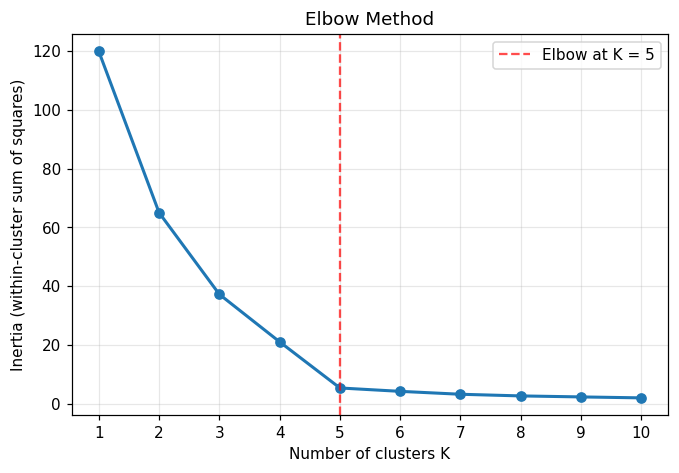

In [19]:
plt.figure(figsize=(7, 4.5))
plt.plot(list(k_values), inertia_values, marker="o", linewidth=2)
plt.axvline(5, color="red", linestyle="--", alpha=0.7, label="Elbow at K = 5")
plt.xlabel("Number of clusters K")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Extra evidence: Silhouette score
The elbow can be subjective, so I also calculate the average silhouette score (from -1 to 1, higher is better; it measures how close each point is to its own cluster compared with the nearest other cluster).

,K,Silhouette
0,2,0.449
1,3,0.524
2,4,0.622
3,5,0.753
4,6,0.702
5,7,0.651
6,8,0.579
7,9,0.495
8,10,0.409


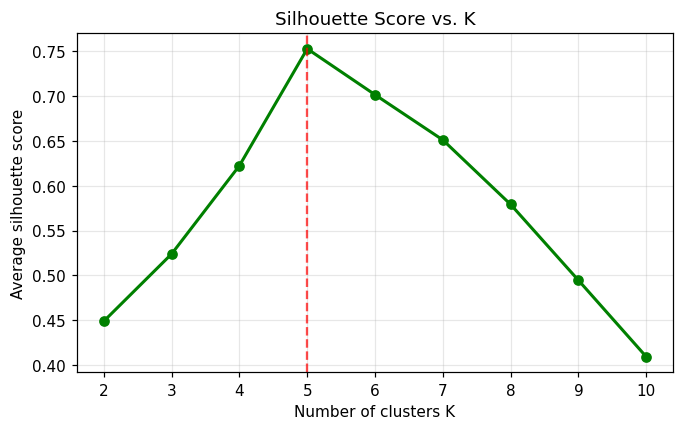

K with the highest silhouette score: 5


In [20]:
sil_scores = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

sil_df = pd.DataFrame({"K": range(2, 11), "Silhouette": sil_scores})
display(sil_df.round(3))

plt.figure(figsize=(7, 4))
plt.plot(sil_df["K"], sil_df["Silhouette"], marker="o", color="green", linewidth=2)
plt.axvline(5, color="red", linestyle="--", alpha=0.7)
plt.xlabel("Number of clusters K")
plt.ylabel("Average silhouette score")
plt.title("Silhouette Score vs. K")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()

best_k = sil_df.loc[sil_df["Silhouette"].idxmax(), "K"]
print("K with the highest silhouette score:", best_k)

### Questions (Task 2)

**What does inertia measure?**  
Inertia is the **sum of squared distances between every point and the centroid of its assigned cluster** (within-cluster sum of squares). It measures how compact the clusters are: the smaller it is, the closer the points are to their centers.

**Why does inertia decrease when the number of clusters increases?**  
With more centroids, every point can be closer to its nearest centroid, so the squared distances can only get smaller (or stay the same). Adding a cluster never increases the optimal inertia. So inertia always decreases with K, which is why we cannot simply pick the K with the lowest inertia, and instead we look for the point where the improvement stops being significant.

**Why would choosing K equal to the number of customers produce a misleadingly low inertia?**  
If K = 40, every customer becomes its own cluster and its own centroid, so every distance is 0 and the **inertia is exactly 0**. That looks "perfect" but the model learned nothing: there is no grouping, no segments and no business value. It is an extreme case of overfitting.

**Where is the elbow point in my graph?**  
At **K = 5**. The inertia falls from 120 (K=1) to 65.0 (K=2), 37.2 (K=3) and 21.0 (K=4), then drops sharply to **5.3 at K=5** (a reduction of about 75% in a single step, the largest of the curve after K=1). After K=5 the improvements are tiny: 5.3 to 4.1 (K=6), then 3.2, 2.6, 2.2 and 1.9 (about 1 unit or less per extra cluster). The curve therefore bends at K=5 and becomes almost flat.

**Why did I select this value of K?**  
Because the experiment supports it, and not because of the description of the dataset:
1. **Elbow:** the last big drop happens when going from K=4 to K=5; adding a 6th cluster only reduces inertia by about 1.1, which just splits an already compact group.
2. **Silhouette:** the average silhouette score is highest at K=5 (about 0.75), compared with about 0.62 for K=4 and about 0.70 for K=6.
3. **Consistency with Task 1:** the K=4 model produced one cluster twice as big as the others (16 vs 8), a sign that two natural groups were merged.

So the data itself suggests **K = 5**, even though the task statement mentions four segments. I will therefore use K = 5 as the final KMeans model and keep the K = 4 result only for comparison.

### Final KMeans model with the selected K = 5

In [21]:
K_FINAL = 5
kmeans5 = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
df["KMeans_Cluster_K5"] = kmeans5.fit_predict(X_scaled)

print("Customers per cluster (K=5):")
print(df["KMeans_Cluster_K5"].value_counts().sort_index())

# Segment profiles in original units
profile = (df.groupby("KMeans_Cluster_K5")[features].mean().round(1)
             .join(df["KMeans_Cluster_K5"].value_counts().rename("Size")))
profile

Customers per cluster (K=5):
KMeans_Cluster_K5
0    8
1    8
2    8
3    8
4    8
Name: count, dtype: int64


,Annual Income (k$),Spending Score (1-100),Age,Size
KMeans_Cluster_K5,,,,
0,83.9,87.2,26.4,8
1,21.0,18.6,49.6,8
2,21.9,16.0,24.8,8
3,85.8,17.0,49.6,8
4,21.8,87.2,25.6,8


In [22]:
# Compare K=4 vs. K=5 assignments (crosstab)
pd.crosstab(df["KMeans_Cluster"], df["KMeans_Cluster_K5"],
            rownames=["K=4 cluster"], colnames=["K=5 cluster"])

K=5 cluster,0,1,2,3,4
K=4 cluster,,,,,
0,8,0,0,0,8
1,0,8,0,0,0
2,0,0,8,0,0
3,0,0,0,8,0


The crosstab shows that going from K=4 to K=5 keeps three clusters unchanged and **splits the oversized cluster of 16 customers into two clean groups of 8**: young high-spenders with low income and young high-spenders with high income.

**Segment interpretation (K = 5)**

Use the `profile` table above to name each group. In terms of business meaning, the five segments are:

| Segment | Income | Spending | Age | Suggested name |
|---|---|---|---|---|
| A | Low (about 22k$) | Low (about 16) | Young (about 25) | Budget-conscious young customers |
| B | Low (about 21k$) | Low (about 19) | Older (about 50) | Low-income mature customers |
| C | High (about 86k$) | Low (about 17) | Older (about 50) | Wealthy savers (high potential, under-spending) |
| D | High (about 84k$) | High (about 87) | Young (about 26) | Premium young big-spenders (VIP) |
| E | Low (about 21k$) | High (about 87) | Young (about 25) | Enthusiastic young spenders (spend beyond their income) |

(The cluster *numbers* assigned by KMeans are arbitrary; check the `profile` table to see which number corresponds to which segment.)

## Task 3: KMeans Visualization

### 1. Two-dimensional scatter plot (Income vs. Spending Score)

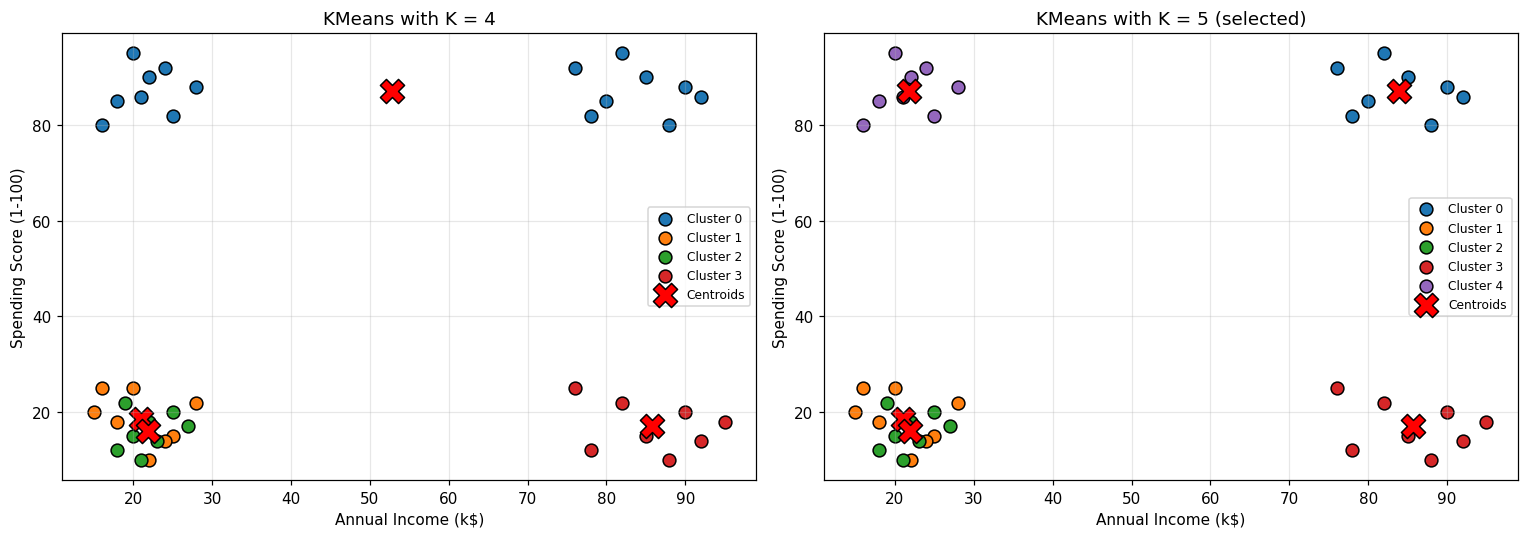

In [23]:
colors = plt.cm.tab10.colors

def plot_kmeans_2d(ax, labels, centers_scaled, title):
    centers = scaler.inverse_transform(centers_scaled)
    for c in sorted(set(labels)):
        mask = labels == c
        ax.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                   s=70, color=colors[c], edgecolor="k", label=f"Cluster {c}")
    ax.scatter(centers[:, 0], centers[:, 1], s=250, c="red", marker="X", edgecolor="k", label="Centroids")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_kmeans_2d(axes[0], df["KMeans_Cluster"].values, kmeans4.cluster_centers_, "KMeans with K = 4")
plot_kmeans_2d(axes[1], df["KMeans_Cluster_K5"].values, kmeans5.cluster_centers_, "KMeans with K = 5 (selected)")
plt.tight_layout()
plt.show()

### 2. Three-dimensional scatter plot (Income, Spending Score, Age)

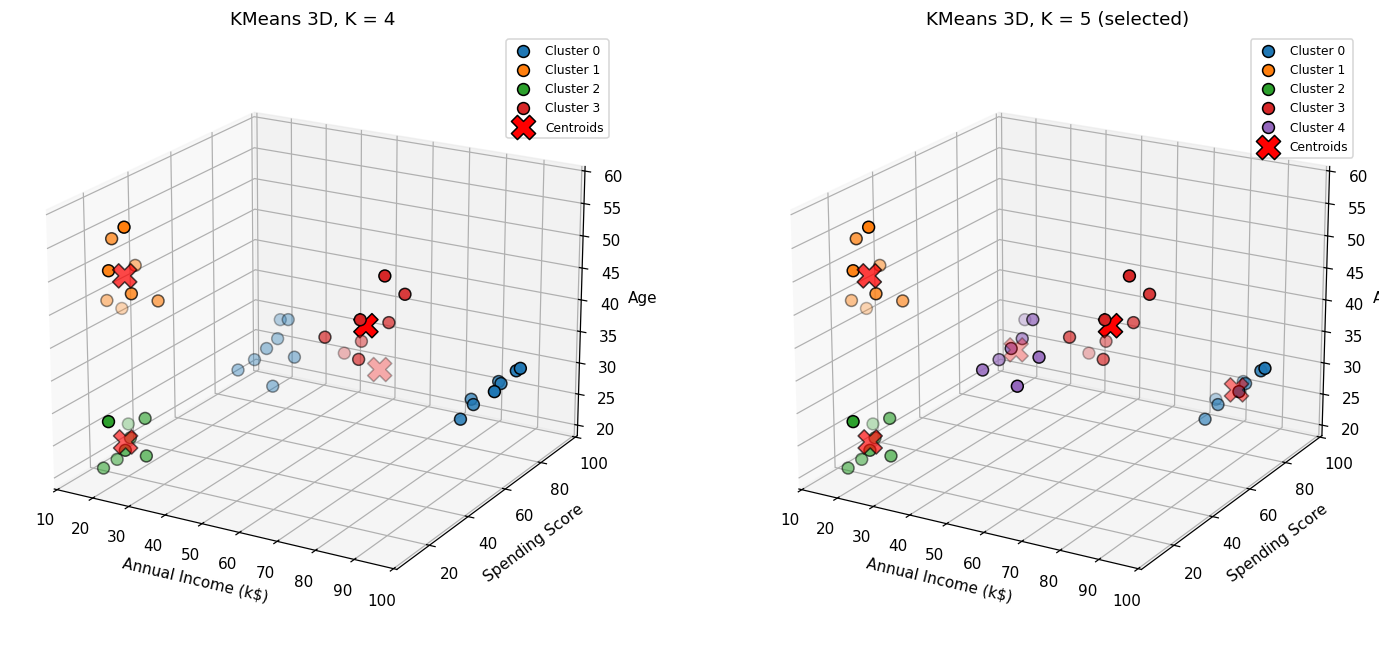

In [24]:
def plot_kmeans_3d(ax, labels, centers_scaled, title, elev=20, azim=-60):
    centers = scaler.inverse_transform(centers_scaled)
    for c in sorted(set(labels)):
        mask = labels == c
        ax.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                   df.loc[mask, "Age"], s=60, color=colors[c], edgecolor="k", label=f"Cluster {c}")
    ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], s=250, c="red", marker="X",
               edgecolor="k", label="Centroids")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score")
    ax.set_zlabel("Age")
    ax.set_title(title)
    ax.view_init(elev=elev, azim=azim)
    ax.legend(fontsize=8)

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
plot_kmeans_3d(ax1, df["KMeans_Cluster"].values, kmeans4.cluster_centers_, "KMeans 3D, K = 4")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plot_kmeans_3d(ax2, df["KMeans_Cluster_K5"].values, kmeans5.cluster_centers_, "KMeans 3D, K = 5 (selected)")
plt.tight_layout()
plt.show()

### 3. Elbow plot

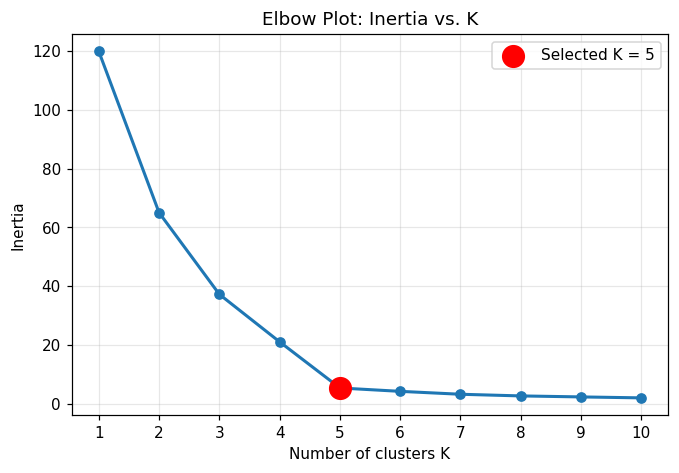

In [25]:
plt.figure(figsize=(7, 4.5))
plt.plot(list(k_values), inertia_values, marker="o", linewidth=2)
plt.scatter([5], [inertia_values[4]], s=200, color="red", zorder=5, label="Selected K = 5")
plt.xlabel("Number of clusters K")
plt.ylabel("Inertia")
plt.title("Elbow Plot: Inertia vs. K")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Analysis of the visualizations

- **Are the groups visually separated?** Yes. With K=5 the clusters are compact and clearly separated, with large empty gaps between them (the silhouette score of about 0.75 confirms this). In the 2D plot, the K=4 solution shows one cluster covering both high-spending young groups (low and high income), which are far apart on the Income axis, so the merge is clearly artificial.
- **Do 2D and 3D give different insights?** Yes.
  - In **2D (Income vs. Spending)** we can only see **four** visible blobs: low/low, high/low, low/high and high/high. The bottom-left blob looks like a single group.
  - In **3D (adding Age)** the bottom-left blob separates into **two groups by age** (young about 21 to 30 vs. older about 43 to 58) with the same low income and low spending. Likewise, the high-income/low-spending group is the older group. So Age is the feature that reveals the **fifth** segment, which is invisible in the 2D plot. This is exactly why the elbow and the silhouette point to K = 5 and not 4.

# Part C: DBSCAN Clustering

## Task 1: Implement DBSCAN (9 experiments)

In [26]:
experiments = [
    (0.3, 3), (0.5, 3), (0.7, 3), (1.0, 3),
    (0.5, 5), (0.7, 5), (1.0, 5),
    (0.7, 8), (1.0, 8),
]

results = []
dbscan_labels = {}          # store the labels of every experiment

for i, (eps, ms) in enumerate(experiments, start=1):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    dbscan_labels[(eps, ms)] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)   # exclude noise label -1
    n_noise = int((labels == -1).sum())
    results.append({"Experiment": i, "eps": eps, "min_samples": ms,
                    "n_clusters": n_clusters, "n_noise_points": n_noise})

dbscan_summary = pd.DataFrame(results).set_index("Experiment")
dbscan_summary

,eps,min_samples,n_clusters,n_noise_points
Experiment,,,,
1,0.3,3,4,18
2,0.5,3,5,0
3,0.7,3,5,0
4,1.0,3,5,0
5,0.5,5,5,2
6,0.7,5,5,0
7,1.0,5,5,0
8,0.7,8,3,16
9,1.0,8,5,0


In [27]:
# Store one of the results as a column, as requested (eps=0.5, min_samples=5)
df["DBSCAN_Cluster"] = dbscan_labels[(0.5, 5)]
df["DBSCAN_Cluster"].value_counts().sort_index()

,count
DBSCAN_Cluster,
-1,2
0,8
1,8
2,8
3,7
4,7


## Task 2: Understand the Parameters

**How DBSCAN works (short reminder):** a point is a **core point** if at least `min_samples` points (including itself) lie within distance `eps`. Clusters are formed by connecting core points that are neighbors, and points that are reachable from a core point become **border points**. Everything else is **noise** (label -1).

To help choose `eps`, here is the **k-distance plot**: for each point, the distance to its 3rd nearest neighbor (sorted). The "knee" of the curve suggests a good `eps`.

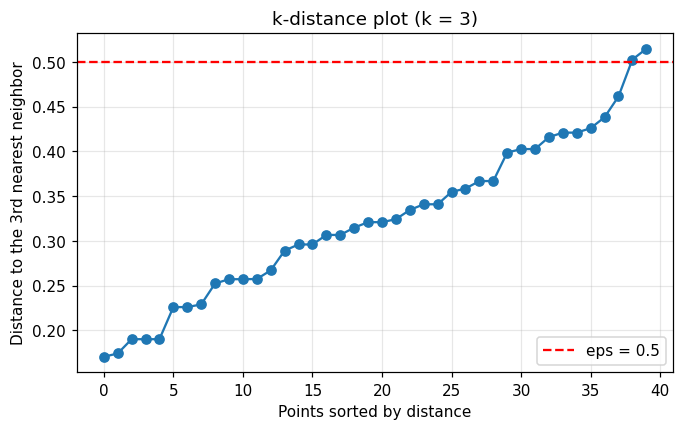

Largest 3-NN distance: 0.515


In [29]:
nn = NearestNeighbors(n_neighbors=3).fit(X_scaled)
k_dist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist, marker="o")
plt.axhline(0.5, color="red", linestyle="--", label="eps = 0.5")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to the 3rd nearest neighbor")
plt.title("k-distance plot (k = 3)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print("Largest 3-NN distance:", k_dist.max().round(3))

### Effect of `eps` (fixed `min_samples`)

| min_samples | eps = 0.3 | 0.5 | 0.7 | 1.0 |
|---|---|---|---|---|
| 3 | 4 clusters, 18 noise | 5 clusters, 0 noise | 5 clusters, 0 noise | 5 clusters, 0 noise |

- **Too small `eps` (0.3):** the neighborhood radius is smaller than the typical spacing inside the groups, so many points do not have enough neighbors and become **noise (18 of 40 points)**, the two older groups are almost entirely lost as noise, and the young high-income/high-spending group is split into two small clusters (only 4 clusters are found, with sizes 7, 3, 5, 7 instead of 8, 8, 8, 8, 8).
- **Moderate `eps` (0.5 to 0.7):** the radius is large enough to connect all the members of each group but much smaller than the gap between different groups, so we recover **5 clean clusters with no noise**.
- **Larger `eps` (1.0):** still gives the same 5 clusters here because the groups are far apart from each other (the gaps between groups are much larger than 1.0 in scaled units). If `eps` were increased much more, nearby clusters would start to **merge** into one big cluster.

### Effect of `min_samples` (fixed `eps`)

| eps | min_samples = 3 | 5 | 8 |
|---|---|---|---|
| 0.5 | 5 clusters, 0 noise | 5 clusters, 2 noise | not tested |
| 0.7 | 5 clusters, 0 noise | 5 clusters, 0 noise | **3 clusters, 16 noise** |
| 1.0 | 5 clusters, 0 noise | 5 clusters, 0 noise | 5 clusters, 0 noise |

- A larger `min_samples` makes the algorithm **stricter**: a point needs more neighbors to be a core point. Since every real group in this dataset has only **8 customers**, `min_samples = 8` requires that *every* member of the group (the point itself plus the 7 others) is inside the radius. With `eps = 0.7` this fails for two groups, so they are lost as **noise** (16 points = 2 groups) and only 3 clusters remain.
- With `eps = 0.5, min_samples = 5`, two points on the edge of their groups fail the density requirement and become noise.
- Increasing `eps` can **compensate** for a large `min_samples` (`eps = 1.0, min_samples = 8` recovers all 5 clusters).

### Summary
- `eps` controls the **size of the neighborhood**: small gives noise and fragmentation, large gives merging.
- `min_samples` controls the **density threshold**: small gives few noise points, large gives more noise and fewer/smaller clusters. It should be smaller than the size of the smallest real group.
- The two parameters interact, and the results are **sensitive** to them, unlike KMeans where we mainly choose K.
- Stable region for this data: `eps` between 0.5 and 1.0 with `min_samples` between 3 and 5 gives the same 5 clusters.

## Task 3: DBSCAN Visualization

I selected four combinations that give meaningfully different outcomes:

| Combination | Result |
|---|---|
| eps=0.3, min_samples=3 | 4 clusters, 18 noise (too strict) |
| eps=0.5, min_samples=5 | 5 clusters, 2 noise (almost perfect) |
| eps=0.7, min_samples=8 | 3 clusters, 16 noise (min_samples too high) |
| eps=0.7, min_samples=5 | 5 clusters, 0 noise (clean result) |

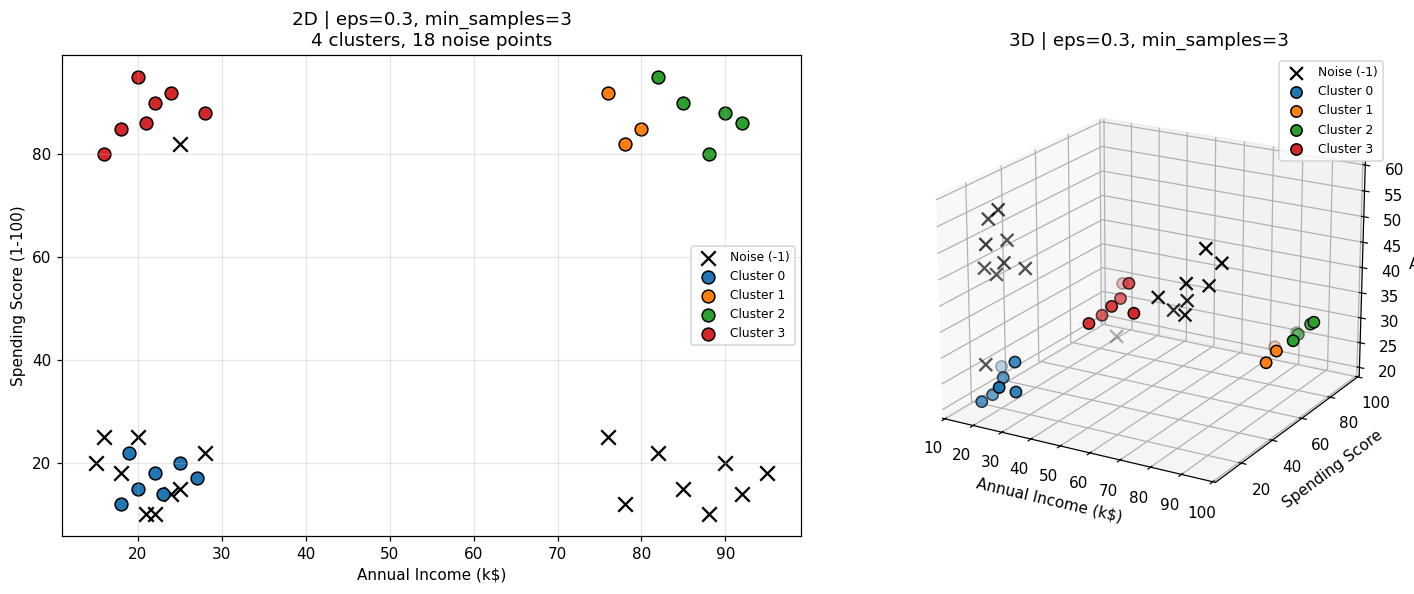

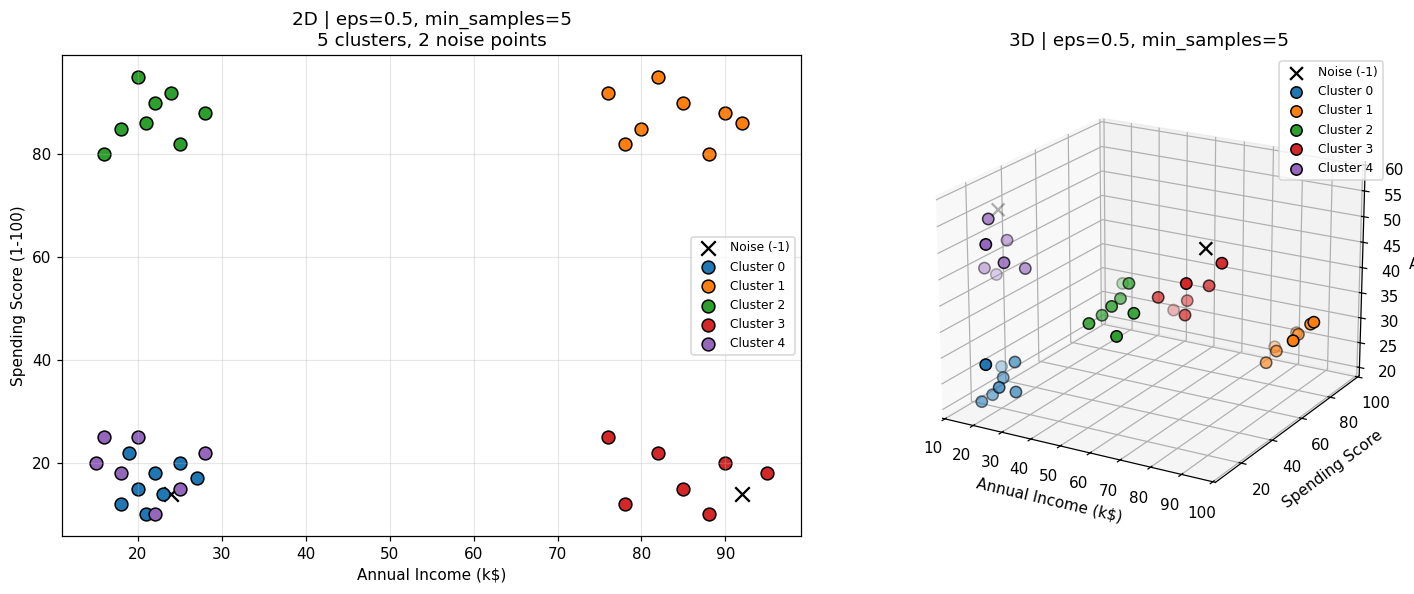

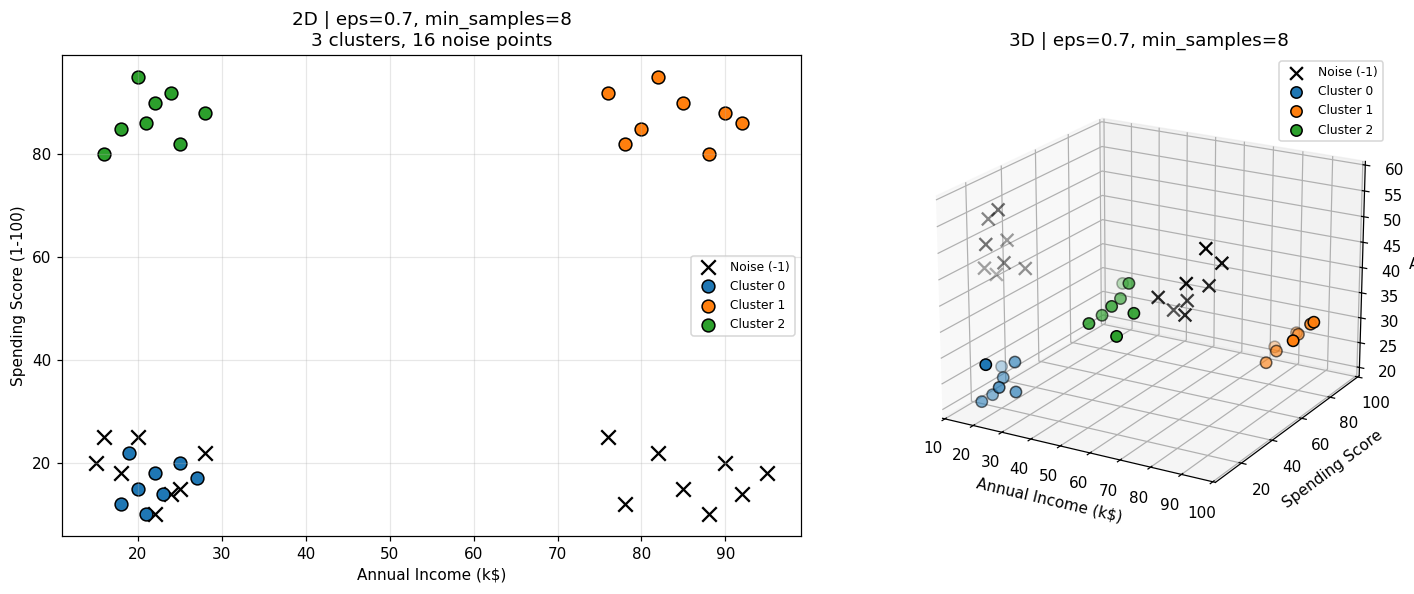

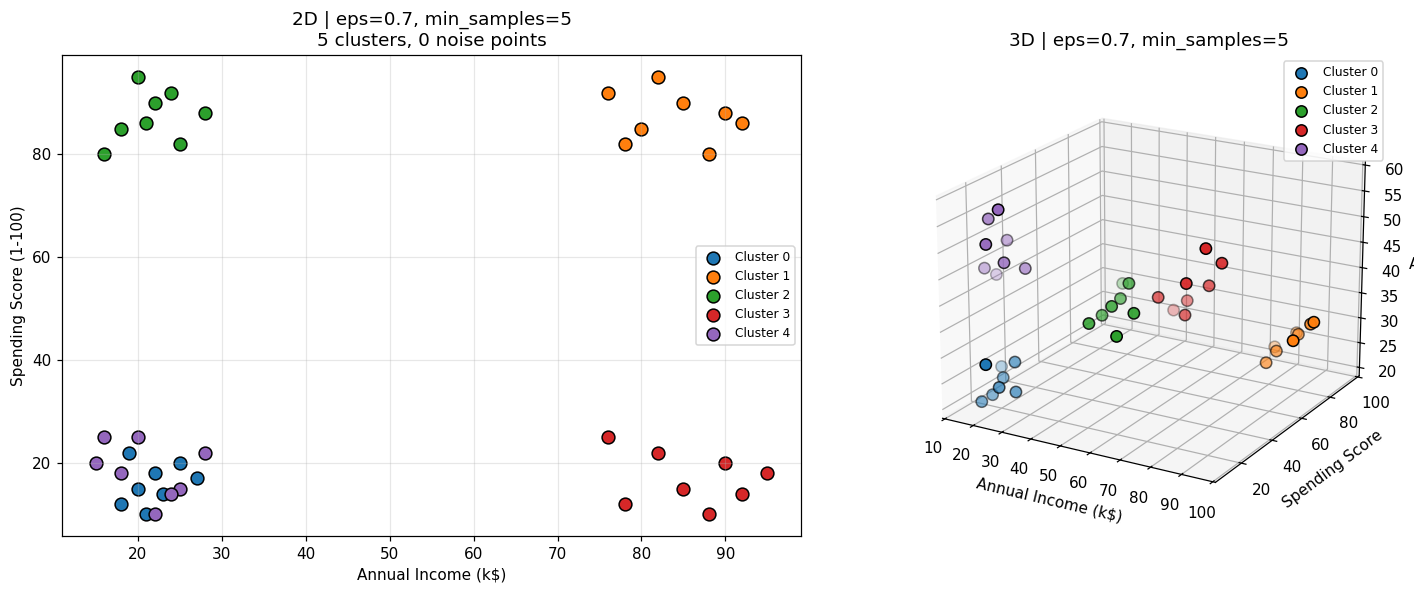

In [30]:
selected = [(0.3, 3), (0.5, 5), (0.7, 8), (0.7, 5)]

def plot_dbscan(eps, ms):
    labels = dbscan_labels[(eps, ms)]
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()

    fig = plt.figure(figsize=(14, 5.5))
    ax2d = fig.add_subplot(1, 2, 1)
    ax3d = fig.add_subplot(1, 2, 2, projection="3d")

    for c in sorted(set(labels)):
        mask = labels == c
        if c == -1:
            ax2d.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                         c="black", marker="x", s=90, label="Noise (-1)")
            ax3d.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                         df.loc[mask, "Age"], c="black", marker="x", s=70, label="Noise (-1)")
        else:
            ax2d.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                         color=colors[c % 10], s=70, edgecolor="k", label=f"Cluster {c}")
            ax3d.scatter(df.loc[mask, "Annual Income (k$)"], df.loc[mask, "Spending Score (1-100)"],
                         df.loc[mask, "Age"], color=colors[c % 10], s=55, edgecolor="k", label=f"Cluster {c}")

    ax2d.set_xlabel("Annual Income (k$)"); ax2d.set_ylabel("Spending Score (1-100)")
    ax2d.set_title(f"2D | eps={eps}, min_samples={ms}\n{n_clusters} clusters, {n_noise} noise points")
    ax2d.grid(alpha=0.3); ax2d.legend(fontsize=8)

    ax3d.set_xlabel("Annual Income (k$)"); ax3d.set_ylabel("Spending Score"); ax3d.set_zlabel("Age")
    ax3d.set_title(f"3D | eps={eps}, min_samples={ms}")
    ax3d.view_init(elev=20, azim=-60); ax3d.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

for eps, ms in selected:
    plot_dbscan(eps, ms)

### Comparison of the DBSCAN visualizations

- **eps = 0.3, min_samples = 3 (too strict):** the radius is so small that many points lose their neighbors, so **18 points are noise** (black crosses) and the groups look incomplete or fragmented. Only parts of the real groups survive as clusters.
- **eps = 0.5, min_samples = 5:** almost the correct segmentation, with 5 clusters and only 2 edge points left as noise. The boundary points of the groups are the first ones to fail the density requirement.
- **eps = 0.7, min_samples = 8:** `min_samples` equals the size of each real group, so only the groups tight enough to satisfy it survive. **Two entire groups (16 points) are classified as noise**, and just 3 clusters are found. This shows that a large `min_samples` can make the algorithm discard real segments.
- **eps = 0.7, min_samples = 5:** the clean solution: 5 compact clusters, no noise.

**Number, shape and separation:** `eps` and `min_samples` change the *number* of clusters (4, 5 or 3 here) and the amount of noise, while the *shape* of each cluster is decided by the density of the points: DBSCAN can follow any shape, whereas here the groups are compact blobs, so the clean runs look like KMeans clusters. Since the real groups are far from each other, the separation is clear once the parameters are in the right range. In the 3D view the age dimension separates the older customers from the young ones, which is why the low-income/low-spending customers form two different clusters rather than one.

# Part D: KMeans vs. DBSCAN

Before the table, a direct numerical comparison between the best KMeans model (K=5) and a clean DBSCAN run (eps=0.7, min_samples=5).

In [31]:
km_labels = df["KMeans_Cluster_K5"].values
db_labels = dbscan_labels[(0.7, 5)]

print("Adjusted Rand Index (KMeans K=5 vs DBSCAN eps=0.7/ms=5):",
      round(adjusted_rand_score(km_labels, db_labels), 3))
print("Silhouette KMeans K=5 :", round(silhouette_score(X_scaled, km_labels), 3))
print("Silhouette DBSCAN     :", round(silhouette_score(X_scaled, db_labels), 3))

print("\nKMeans K=4 vs KMeans K=5 -> ARI:",
      round(adjusted_rand_score(km_labels, df["KMeans_Cluster"].values), 3))

Adjusted Rand Index (KMeans K=5 vs DBSCAN eps=0.7/ms=5): 1.0
Silhouette KMeans K=5 : 0.753
Silhouette DBSCAN     : 0.753

KMeans K=4 vs KMeans K=5 -> ARI: 0.764


Both algorithms give **identical groupings** (ARI = 1) when the data is well separated and their parameters are chosen well. The differences appear in how they get there, and in what happens when the data or the parameters are less ideal.

## Comparison table

| Comparison criterion | KMeans | DBSCAN |
|---|---|---|
| **Main parameters** | `n_clusters` (K) (plus `n_init`, `random_state`) | `eps` (radius) and `min_samples` (density threshold) |
| **Requires the number of clusters beforehand?** | **Yes.** K must be supplied; we estimate it with the elbow method or the silhouette score (here K=5). With a wrong K, groups are merged (K=4) or split (K>5). | **No.** The number of clusters is a *result* of the density structure and the parameters (3, 4 or 5 clusters in our experiments). But we must tune `eps` and `min_samples`, which indirectly control it. |
| **Cluster assignment approach** | **Centroid-based**, partitioning. Iteratively assigns every point to the nearest centroid and recomputes centroids. Every point belongs to exactly one cluster. | **Density-based.** Clusters are dense regions connected through core points (points with at least `min_samples` neighbors within `eps`). Not every point has to be assigned. |
| **Can identify noise points?** | **No.** Every point, including outliers, is forced into a cluster and can pull the centroids. | **Yes.** Points in low-density regions get the label -1 (for example 18 noise points with eps=0.3/min_samples=3). |
| **Sensitivity to feature scaling** | **High.** Uses Euclidean distance to centroids, so large-range features dominate. | **High.** Uses Euclidean distance with a single `eps`; on unscaled data our `eps` values made all 40 points noise. Scaling is essential. |
| **Suitable for non-spherical clusters?** | **No.** Tends to find convex / spherical clusters of similar size because it separates points by distance to centroids. | **Yes.** Can find arbitrarily shaped clusters (rings, moons, elongated shapes), as long as they have uniform density. |

## Additional observations from our experiments

- **Stability:** KMeans with a good K gave the correct grouping, and the result was reproducible with `random_state=42, n_init=10`. DBSCAN was far more **sensitive to parameters**: the same data produced 3, 4 or 5 clusters and between 0 and 18 noise points.
- **When each one wins:** for compact, similar-sized groups and when we need *every* customer assigned to a segment (marketing campaigns), KMeans with the elbow method is simple and effective. DBSCAN is better when we expect outliers or irregular shaped groups and do not know K.
- **Weakness of DBSCAN:** a single `eps` cannot handle clusters with very different densities, and large `min_samples` can discard small but real segments (like the 16 customers lost at eps=0.7/min_samples=8).
- **Weakness of KMeans:** a wrong K silently produces misleading segments (the K=4 model merged two different customer types).

# Conclusion

1. The data is clean (no missing values, no duplicates) and was standardized with `StandardScaler`, which is required for both distance-based algorithms.
2. The elbow method (largest drop between K=4 and K=5, then almost flat) and the silhouette score (maximum of about 0.75 at K=5) both indicate **K = 5**. The task statement mentions four segments, but the data actually contains **five** well separated groups of 8 customers. The fifth is only visible when Age is added (3D view).
3. The five customer segments are: young low-income low-spenders, older low-income low-spenders, older high-income low-spenders, young high-income high-spenders, and young low-income high-spenders.
4. DBSCAN recovers the same five groups with `eps` in [0.5, 1.0] and `min_samples` in [3, 5], but with a very small `eps` or a very large `min_samples` it labels many real customers as noise.
5. KMeans needs K but gives a full partition. DBSCAN does not need K and detects noise, but depends on the parameters `eps` and `min_samples`.

**Business recommendation:** target the *wealthy savers* (high income, low spending) with premium offers, since they have the highest unused potential; keep rewarding the *premium young big-spenders*; and use budget-friendly promotions for the low-income segments.